In [1]:
from aaindex.aaindex import aaindex

In [2]:
full_record = aaindex['CHOP780206']   #get full AAI record

In [3]:
full_record

{'category': 'sec_struct',
 'description': 'Normalized frequency of N-terminal non helical region (Chou-Fasman, 1978b)',
 'notes': '',
 'refs': "Chou, P.Y. and Fasman, G.D. 'Prediction of the secondary structure of proteins from their amino acid sequence' Adv. Enzymol. 47, 45-148 (1978); Kawashima, S. and Kanehisa, M.                     'AAindex: amino acid index database.'  Nucleic Acids Res. 28, 374 (2000).",
 'values': {'-': 0,
  'A': 0.7,
  'C': 0.65,
  'D': 0.98,
  'E': 1.04,
  'F': 0.93,
  'G': 1.41,
  'H': 1.22,
  'I': 0.78,
  'K': 1.01,
  'L': 0.85,
  'M': 0.83,
  'N': 1.42,
  'P': 1.1,
  'Q': 0.75,
  'R': 0.34,
  'S': 1.55,
  'T': 1.09,
  'V': 0.75,
  'W': 0.62,
  'Y': 0.99}}

In [4]:
full_record['values']

{'-': 0,
 'A': 0.7,
 'C': 0.65,
 'D': 0.98,
 'E': 1.04,
 'F': 0.93,
 'G': 1.41,
 'H': 1.22,
 'I': 0.78,
 'K': 1.01,
 'L': 0.85,
 'M': 0.83,
 'N': 1.42,
 'P': 1.1,
 'Q': 0.75,
 'R': 0.34,
 'S': 1.55,
 'T': 1.09,
 'V': 0.75,
 'W': 0.62,
 'Y': 0.99}

In [5]:
help(aaindex)

Help on AAIndex in module aaindex.aaindex object:

class AAIndex(builtins.object)
 |          Python parser for AAindex1: Amino Acid Index Database
 |                    (**abbreviated to AAI onwards**)
 |  The AAindex is a database of numerical indices representing various physiochemical
 |  and biochemical properties of amino acids and pairs of amino acids. This class 
 |  stores the amino acid index of 20 numerical values for the 20 amino acids 
 |  (http://www.genome.jp/aaindex/).
 |  Some of the parsing functionality is patrially inspired off the AAIndex1 parser
 |  by harmslab: https://github.com/harmslab/hops/blob/master/hops/features/data/util/aaindex2json.py
 |  
 |  Data format of AAI1:
 |  ************************************************************************
 |  *                                                                      *
 |  * Each entry has the following format.                                 *
 |  *                                                          

In [6]:
#get individual elements of AAIndex record
record_values = aaindex['CHOP780206']['values']
record_description = aaindex['CHOP780206']['description']
record_references = aaindex['CHOP780206']['refs']

In [7]:
record_values

{'-': 0,
 'A': 0.7,
 'C': 0.65,
 'D': 0.98,
 'E': 1.04,
 'F': 0.93,
 'G': 1.41,
 'H': 1.22,
 'I': 0.78,
 'K': 1.01,
 'L': 0.85,
 'M': 0.83,
 'N': 1.42,
 'P': 1.1,
 'Q': 0.75,
 'R': 0.34,
 'S': 1.55,
 'T': 1.09,
 'V': 0.75,
 'W': 0.62,
 'Y': 0.99}

In [8]:
IMPORTANT_PROPERTIES_FROM_PAPER = [
    "GEIM800103",
    "OOBM770104",
    "QIAN880132",
    "OOBM850102",
    "NADH010106",
    "RADA880106",
    "QIAN880112",
    "WEBA780101",
    "QIAN880125",
    "JOND750101",
    "QIAN880124"
]

# Read data, models and paths

In [9]:
import collections

import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

In [10]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/alleles_with_groups/"
# TARGET_LENGTHS = [9, 10]
TARGET_LENGTHS = [ 13, 14, 15, 16, 17, 18]
models_to_read = ['bw']

In [11]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = list(sorted(get_available_alleles(DATA_PATH)))
ALLELES = [   'HLA-DRB1*01:01'

    # 'HLA-A*01:01',
           # 'HLA-A*03:01',
           # 'HLA-A*02:01'
          ]

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

# ALLELES = ['HLA-A*01:01', 'HLA-A*03:01']
ALLELES

['HLA-DRB1*01:01']

## Also add immunogenic data

In [12]:
from os import listdir
from os.path import isfile, join
from mhcnames import normalize_allele_name
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/immunogenic/' # windows

onlyfiles = [f for f in listdir(DATA_PATH) if isfile(join(DATA_PATH, f))]
IMM_ALLELES = []
per_allele_imm_df = dict()
for file_name in onlyfiles:
    allele_name = file_name.split("_", 1)[1].split('.')[0]
    allele_name = normalize_allele_name(allele_name)
    per_allele_imm_df[allele_name] =  pd.read_csv(DATA_PATH + file_name,sep=";")
    IMM_ALLELES.append(allele_name)
IMM_ALLELES

['HLA-A*01:01', 'HLA-A*02:01', 'HLA-A*03:01', 'HLA-B*07:02', 'HLA-B*27:05']

In [13]:
IMM_ALLELES

['HLA-A*01:01', 'HLA-A*02:01', 'HLA-A*03:01', 'HLA-B*07:02', 'HLA-B*27:05']

In [14]:
from data_reading_methods import get_available_alleles, read_data
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/immunogenic/per_length_per_kfold_split/' # windows

def merge_imm_data_to_binders_data_as_new_alleles(per_allele_per_kfold_per_length_binders, per_allele_imm_data):
    for allele in ALLELES:
        if allele in IMM_ALLELES:
            new_allele = allele + "_imm"

            per_allele_per_kfold_per_length_binders[new_allele] = dict()
            # per_length_peptides = defaultdict(list)

            # for kfold, per_length_imm_peptides in per_allele_per_kfold_per_length_imm[allele].items():
            #     for target_length, peptides in per_length_imm_peptides.items():
            #         per_length_peptides[target_length].extend(peptides)
            for kfold, per_length_peptides in per_allele_per_kfold_per_length_binders[allele].items():
                per_allele_per_kfold_per_length_binders[new_allele][kfold] = dict()
                for target_length in per_length_peptides.keys():
                    imm_df = per_allele_imm_data[allele]
                    imm_df = imm_df[imm_df['immunogenic'] == 1]
                    imm_df = imm_df[imm_df['length'] == target_length]
                    per_allele_per_kfold_per_length_binders[new_allele][kfold][target_length] = imm_df['peptide'].values

merge_imm_data_to_binders_data_as_new_alleles(per_allele_per_kfold_per_length_binders_train, per_allele_imm_df)
merge_imm_data_to_binders_data_as_new_alleles(per_allele_per_kfold_per_length_binders_test, per_allele_imm_df)


In [15]:
per_allele_per_kfold_per_length_binders_test.keys()

dict_keys(['HLA-DRB1*01:01'])

# Read models

In [16]:
# MODELS PARAMS
## PARAMETERS
RUNS = 5
# RUNS = 5
total_splits = 1
SELECTED_RUN = 0
SELECTED_RUN = {0,1,2,3,4,
             #   5, 6, 7, 8, 9
               }
# SELECTED_RUN = {0,1
#                 }

SELECTED_SPLIT = 0

MODELS_DESCRIPTIONS = {
    "single_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10],
    },
    "single_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": [
            #'HLA-A*01:01',
            'HLA-A*03:01',
            #'HLA-A*02:01'
        ],
        "target_lengths": [9, 10]
    },
        "single_allele_balanced_class2": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },
            "single_allele_balanced_class2_biger": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 35,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },
    "multiple_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01',
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },
    "multiple_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01',
                    'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10]
        },
        "single_allele_balanced_class2_joiners": {
        "path": "experiment_results/alleles_with_groups_and_joiner_states_single_allele_balanced_data/",
        "states": 49,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [13, 14, 15, 16, 17, 18]},
    "groups_retrain_single_allele_balanced_data": {
        "path": "experiment_results/groups_retrain_single_allele_balanced_data/",
        "states": 45,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [10, 11, 12, 13, 14, 15, 16, 17, 18]},
    "anchor_model_5_single_allele_balanced_data": {
        "path": "experiment_results/groups_retrain_single_allele_balanced_data/anchor_models/",
        "states": 37,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [10, 11, 12, 13, 14, 15, 16, 17, 18]},

        "anchor_model_5_single_allele_balanced_data_attempt2": {
        "path": "experiment_results/groups_retrain_single_allele_balanced_data/anchor_models/",
        "states": 35,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [10, 11, 12, 13, 14, 15, 16, 17, 18]},
    "anchor_model_5_single_allele_balanced_data_attempt3": {
        "path": "experiment_results/groups_retrain_single_allele_balanced_data/anchor_models/",
        "states": 38,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [10, 11, 12, 13, 14, 15, 16, 17, 18]},
    "single_allele_with_cycle_base_model": {
        "path": "experiment_results/single_allele_balanced_data_base_model/",
        "states": 25,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [13, 14, 15, 16, 17, 18],
        "core_start_state": 25,
        "core_end_state": 26

    }
    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

In [17]:
selected_models = [
                 #'single_allele_imbalanced',
                #'multiple_allele_imbalanced',
                  # 'single_allele_balanced',
                     # 'multiple_allele_balanced',
                # 'single_allele_balanced_class2',
    # 'single_allele_balanced_class2_biger'
    'single_allele_with_cycle_base_model'
]

In [18]:
from hmm_logic_methods import load_model

In [19]:
import itertools


target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
max_target_length = max(TARGET_LENGTHS)
total_splits = 1


name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_general_type = dict()
name_to_model_root = dict()
selected_binding_models = list()
per_name_binding_model = dict()
name_to_target_lengths = dict()
name_to_acceptable_alleles = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type, model_general_type, acceptable_alleles):
    # print(model_name)
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv"]
    name_to_type[model_name] = model_type
    name_to_general_type[model_name] = model_general_type
    name_to_acceptable_alleles[model_name] = acceptable_alleles



for model_general_type in selected_models:
    print(model_general_type)
    model_description = MODELS_DESCRIPTIONS[model_general_type]
    combination_size = model_description['combination_size']
    model_class_alleles = model_description['alleles'] # just alleles used in all training process (the actual value could be less alleles)
    MODELS_PATH = model_description['path']
    params_string = model_description['params_string']
    states = model_description['states']
    TARGET_LENGTHS = model_description['target_lengths']
    target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
    MIXED_ALLELES = list()
    for combination in itertools.combinations(sorted(model_class_alleles), combination_size):
        allele_name = "+".join(combination)
        # allele_name = f"{allele_name1}+{allele_name2}"
        MIXED_ALLELES.append(allele_name)
    for allele_name in MIXED_ALLELES:
        model_alleles = allele_name.split("+")

        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
        for run_num_b in range(RUNS):
            for split_num_b in range(total_splits):
                #bw
                if "bw" in models_to_read:
                    bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, "bw", model_general_type, model_alleles)
                #bwv
                if "bwv" in models_to_read:
                    bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}_plus_viterbi"
                    populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, "bwv", model_general_type, model_alleles)
                #v
                if "v" in models_to_read:
                    v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, "v", model_general_type, model_alleles)



for model_name in selected_binding_models:
    per_name_binding_model[model_name] =  load_model(name_to_model_root[model_name], model_name)


single_allele_with_cycle_base_model


In [20]:
list(per_name_binding_model.keys())

['0_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DRB1_01_01-0',
 '1_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DRB1_01_01-0',
 '2_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DRB1_01_01-0',
 '3_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DRB1_01_01-0',
 '4_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DRB1_01_01-0']

## Select run and split

In [21]:
for model_key in list(per_name_binding_model.keys()):
    if name_to_split[model_key] != SELECTED_SPLIT:
        del per_name_binding_model[model_key]
    elif type(SELECTED_RUN) == set:
        if name_to_run[model_key] not in SELECTED_RUN:
            del per_name_binding_model[model_key]
    elif name_to_run[model_key] != SELECTED_RUN:
        del per_name_binding_model[model_key]
per_name_binding_model = dict(reversed(sorted(per_name_binding_model.items(), key=lambda item: item[0])))

# Populate path embeddings for all models
Here we have already read our models and train/test data.
Now we want to extract representaion of our data for selected models.



In [22]:
#Params
TOP = 1000
global_selected_alleles = ALLELES # Data alleles we selected (but the number will be reduced by acceptable alleles)
imm_global_selected_alleles = [allele_name + "_imm"  for allele_name in global_selected_alleles if allele_name != 'HLA-DRB1*01:01']
total_selected_alleles =global_selected_alleles + imm_global_selected_alleles

In [23]:
global_selected_alleles

['HLA-DRB1*01:01']

## Merge train data together (Take unique peptides from each allele) (will change to outside dataframe in the future)
* Handle intersections (remove for now)
* Take equal portions for each length and allele (for visualization purposes)

In [24]:
# %%time
from collections import defaultdict

selected_alleles = global_selected_alleles


per_allele_representations_train = dict()
per_allele_representations_test = dict()
per_name_representation_train = dict()
per_name_representation_test = dict()

def handle_intersections(per_allele_per_kfold_per_length_peptides):
    per_allele_result_peptide_sets =  defaultdict(set)
    per_allele_per_length_peptide_sets =  defaultdict(set)
    PER_LENGTH_SIZE = {target_length: min([len(set(per_allele_per_kfold_per_length_peptides[allele_name][0][target_length])) for allele_name in selected_alleles]) for target_length in TARGET_LENGTHS}
    print("Min unique sizes", PER_LENGTH_SIZE)
    for target_length in TARGET_LENGTHS:
        print(f"Length {target_length}")
        for allele_name in selected_alleles + imm_global_selected_alleles:
            if target_length in per_allele_per_kfold_per_length_peptides[allele_name][0]:
                print(f"initial length for  allele { allele_name} TL {target_length} is {len(per_allele_per_kfold_per_length_peptides[allele_name][0][target_length])}")
                print(f"unique length for  allele { allele_name} TL {target_length} is {len(set(per_allele_per_kfold_per_length_peptides[allele_name][0][target_length]))}")
                unique_peptides = np.unique(per_allele_per_kfold_per_length_peptides[allele_name][0][target_length])
                if "imm" not in allele_name: #do not subsambple for imm
                    peptides = set(np.random.choice(unique_peptides, size=PER_LENGTH_SIZE[target_length], replace=False))
                else:
                    peptides = set(unique_peptides)
                print(f"Selected/Subsampled {len(peptides)} peptides")
                per_allele_per_length_peptide_sets[allele_name] = peptides
        # get all intersections
        intersections = list()
        for i in range(len(selected_alleles)):
            for j in range(i + 1, len(selected_alleles)):
                set1 = per_allele_per_length_peptide_sets[selected_alleles[i]]
                set2 = per_allele_per_length_peptide_sets[selected_alleles[j]]
                intersect = set1.intersection(set2)
                print(f"{selected_alleles[i]} intersect {selected_alleles[j]} - {len(intersect)}")
                intersections.append(intersect)
        # delete all intersections
        for allele_name, peptide_set in per_allele_per_length_peptide_sets.items():
            print(f"Allele {allele_name}: deleted", end=" ")
            initial_length = len(peptide_set)
            for intersect in intersections:
                peptide_set = peptide_set.difference(intersect)
            result_length = len(peptide_set)
            print(f" {initial_length - result_length} of intersected peptides")
            per_allele_result_peptide_sets[allele_name] = per_allele_result_peptide_sets[allele_name].union(peptide_set)
    return per_allele_result_peptide_sets

print("Train")
per_allele_peptide_train_sets = handle_intersections(per_allele_per_kfold_per_length_binders_train)
print("Test")
per_allele_peptide_test_sets = handle_intersections(per_allele_per_kfold_per_length_binders_test)



train_peptides_b = set(set().union(*per_allele_peptide_train_sets.values()))

test_peptides_b = set(set().union(*per_allele_peptide_test_sets.values()))

print(f"Train {len(train_peptides_b)}, Test {len(test_peptides_b)}")


Train
Min unique sizes {13: 797, 14: 1174, 15: 6675, 16: 1404, 17: 978, 18: 648}
Length 13
initial length for  allele HLA-DRB1*01:01 TL 13 is 826
unique length for  allele HLA-DRB1*01:01 TL 13 is 797
Selected/Subsampled 797 peptides
Allele HLA-DRB1*01:01: deleted  0 of intersected peptides
Length 14
initial length for  allele HLA-DRB1*01:01 TL 14 is 1184
unique length for  allele HLA-DRB1*01:01 TL 14 is 1174
Selected/Subsampled 1174 peptides
Allele HLA-DRB1*01:01: deleted  0 of intersected peptides
Length 15
initial length for  allele HLA-DRB1*01:01 TL 15 is 6886
unique length for  allele HLA-DRB1*01:01 TL 15 is 6675
Selected/Subsampled 6675 peptides
Allele HLA-DRB1*01:01: deleted  0 of intersected peptides
Length 16
initial length for  allele HLA-DRB1*01:01 TL 16 is 1413
unique length for  allele HLA-DRB1*01:01 TL 16 is 1404
Selected/Subsampled 1404 peptides
Allele HLA-DRB1*01:01: deleted  0 of intersected peptides
Length 17
initial length for  allele HLA-DRB1*01:01 TL 17 is 984
uniqu

# Calculate paths embeddings (01.05.2022)

In [25]:
from hmm_logic_methods import  get_model_representation
from ast import literal_eval
def load_paths_df(model, type='viterbi'):
    print(f"model {model.name}")
    TARGET_PATH_TO_FILES = name_to_model_root[model.name] + model.name
    if type == 'viterbi':
        paths_df = pd.read_csv("{}/viterbi_paths_df.csv".format(TARGET_PATH_TO_FILES),sep=";",)
    else:
        paths_df = pd.read_csv("{}/total_paths_df.csv".format(TARGET_PATH_TO_FILES),sep=";")
    # paths_df['path'] = paths_df['path'].apply(pd.eval)
    # paths_df['path'] = paths_df['path'].astype(list)
    return  paths_df

# Get top paths
def save_embeddingds(embedding, model, type_of_data='train'):
    print(f"model {model.name}")
    TARGET_PATH_TO_FILES =  name_to_model_root[model.name] + model.name
    assert embedding['allele'].isnull().sum() == 0
    embedding.to_csv("{}/{}_embedding.csv".format(TARGET_PATH_TO_FILES, type_of_data),sep=";", index=True)

In [26]:
%%time
for model_key, model in sorted(per_name_binding_model.items()):
    print("New model key here: ", model_key)
    #preparation. Read predefined paths df
    df_paths = load_paths_df(model)
    break


New model key here:  0_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DRB1_01_01-0
model 0_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DRB1_01_01-0
Wall time: 319 ms


In [27]:
df_paths['simplified_path'] = df_paths['simplified_path'].apply(lambda x : np.fromstring(x[1:-1], dtype=int, sep=' '))
df_paths  = df_paths[df_paths['simplified_path'].apply(sum) > 0]
df_paths['core_start'] = df_paths['simplified_path'].apply(lambda x: np.where(np.array(x) > 0)[0][0] )
df_paths['core_end'] = df_paths['simplified_path'].apply(lambda x: np.where(np.array(x) > 0)[0][-1])
df_paths['core_len'] = df_paths['core_end'] - df_paths['core_start'] + 1

In [1]:
df_paths

NameError: name 'df_paths' is not defined

In [29]:
df_paths.groupby('core_len')['normalized_prob'].mean()

core_len
1    -0.957557
2    -1.025770
3    -0.890768
4    -0.899164
5    -0.939127
6    -0.781981
7    -0.900769
8    -0.827145
9    -0.720419
10   -0.802275
11   -0.807146
12   -0.896403
13   -1.039447
Name: normalized_prob, dtype: float64

In [30]:
df_paths['core_start'].value_counts()

5     7746
4     7362
3     7135
6     6694
7     4991
2     3780
8     3197
9     1482
1     1039
10     730
11     343
12     148
13      40
14      18
Name: core_start, dtype: int64

In [31]:
df_paths = df_paths[df_paths['core_len'] == 9]

In [32]:
df_paths

,path,simplified_path,prob,normalized_prob,len,mean_viterbi,peptide_cnts,core_start,core_end,core_len
0,grouped_model-start>s027>s025>s002>s004>s007>s...,"[0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0]",-6.236331,-0.389771,14,-47.436744,8907,3,11,9
1,grouped_model-start>s027>s025>s000>s003>s004>s...,"[0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0]",-6.666491,-0.392147,15,-50.634896,7356,4,12,9
2,grouped_model-start>s027>s025>s002>s004>s007>s...,"[0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0]",-6.474022,-0.404626,14,-47.739226,4761,3,11,9
3,grouped_model-start>s027>s025>s000>s003>s004>s...,"[0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0]",-6.904181,-0.406128,15,-51.088704,3647,4,12,9
4,grouped_model-start>s027>s025>s002>s004>s007>s...,"[0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0]",-6.932857,-0.407815,15,-50.725472,7018,3,11,9
...,...,...,...,...,...,...,...,...,...,...
45179,grouped_model-start>s025>s001>s000>s003>s004>s...,"[0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, ...",-23.074921,-1.214470,17,-65.333286,1,4,12,9
45195,grouped_model-start>s027>s025>s001>s004>s008>s...,"[0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0]",-18.316019,-1.221068,13,-44.420982,1,3,11,9
45241,grouped_model-start>s025>s002>s001>s003>s004>s...,"[0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0]",-21.551210,-1.267718,15,-57.648214,1,4,12,9
45244,grouped_model-start>s025>s004>s007>s009>s012>s...,"[0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, ...",-25.615157,-1.280758,18,-69.348814,1,1,9,9


## We are interested in distributions inside core, so try to crop this data

In [33]:
result_paths = list()
result_tr_probs = list()
result_normalized_tr_probs = list()
result_viterbi_probs = list()
result_normalized_vi_probs = list()
for _, (path, simplified_path, tr_prob, norm_tr_prob, path_len, mean_viterbi_prob, peptide_cnts, core_start, core_end, core_len) in df_paths.iterrows():
    source_path = np.array(path.split('>')[1:])
    result_path = source_path[core_start: core_end +1 ]
    result_paths.append(result_path)
    result_tr_probs.append(tr_prob)
    result_normalized_tr_probs.append(norm_tr_prob)
    result_viterbi_probs.append(mean_viterbi_prob)
    result_normalized_vi_probs.append(mean_viterbi_prob/path_len/peptide_cnts)

In [34]:
df = pd.DataFrame({"path": result_paths, "tr_prob": result_tr_probs, "norm_tr_prob": result_normalized_tr_probs , "mean_viterbi": result_viterbi_probs, "norm_viterbi_prob":result_normalized_vi_probs})

In [35]:
df['str_paths'] = df['path'].apply(str)

In [36]:
unique_df = df.drop_duplicates('str_paths')[['path', 'str_paths']].sort_values(by='str_paths')
unique_df

,path,str_paths
4616,"[s004, s005, s007, s006, s011, s013, s015, s02...",['s004' 's005' 's007' 's006' 's011' 's013' 's0...
4444,"[s004, s005, s009, s006, s011, s013, s015, s01...",['s004' 's005' 's009' 's006' 's011' 's013' 's0...
4683,"[s004, s005, s009, s006, s011, s013, s015, s02...",['s004' 's005' 's009' 's006' 's011' 's013' 's0...
5177,"[s004, s005, s009, s012, s010, s013, s015, s02...",['s004' 's005' 's009' 's012' 's010' 's013' 's0...
3378,"[s004, s005, s009, s014, s013, s015, s017, s02...",['s004' 's005' 's009' 's014' 's013' 's015' 's0...
...,...,...
5201,"[s004, s009, s014, s013, s015, s016, s019, s02...",['s004' 's009' 's014' 's013' 's015' 's016' 's0...
4093,"[s004, s009, s014, s013, s015, s017, s024, s02...",['s004' 's009' 's014' 's013' 's015' 's017' 's0...
5161,"[s004, s009, s014, s013, s015, s018, s020, s02...",['s004' 's009' 's014' 's013' 's015' 's018' 's0...
5035,"[s004, s009, s014, s016, s019, s017, s024, s02...",['s004' 's009' 's014' 's016' 's019' 's017' 's0...


In [37]:
unique_df['norm_tr_prob'] = pd.DataFrame(df.groupby('str_paths')['norm_tr_prob'].mean()).sort_values(by='str_paths')['norm_tr_prob'].values
unique_df['norm_vi_prob'] = pd.DataFrame(df.groupby('str_paths')['norm_viterbi_prob'].mean()).sort_values(by='str_paths')['norm_viterbi_prob'].values

In [38]:
unique_df

,path,str_paths,norm_tr_prob,norm_vi_prob
4616,"[s004, s005, s007, s006, s011, s013, s015, s02...",['s004' 's005' 's007' 's006' 's011' 's013' 's0...,-0.883145,-3.574578
4444,"[s004, s005, s009, s006, s011, s013, s015, s01...",['s004' 's005' 's009' 's006' 's011' 's013' 's0...,-0.900109,-3.806719
4683,"[s004, s005, s009, s006, s011, s013, s015, s02...",['s004' 's005' 's009' 's006' 's011' 's013' 's0...,-0.891159,-3.473070
5177,"[s004, s005, s009, s012, s010, s013, s015, s02...",['s004' 's005' 's009' 's012' 's010' 's013' 's0...,-1.046233,-3.852773
3378,"[s004, s005, s009, s014, s013, s015, s017, s02...",['s004' 's005' 's009' 's014' 's013' 's015' 's0...,-0.830213,-3.326631
...,...,...,...,...
5201,"[s004, s009, s014, s013, s015, s016, s019, s02...",['s004' 's009' 's014' 's013' 's015' 's016' 's0...,-1.110272,-3.904437
4093,"[s004, s009, s014, s013, s015, s017, s024, s02...",['s004' 's009' 's014' 's013' 's015' 's017' 's0...,-0.924343,-3.244120
5161,"[s004, s009, s014, s013, s015, s018, s020, s02...",['s004' 's009' 's014' 's013' 's015' 's018' 's0...,-1.049244,-3.723216
5035,"[s004, s009, s014, s016, s019, s017, s024, s02...",['s004' 's009' 's014' 's016' 's019' 's017' 's0...,-0.974014,-3.752873


In [39]:
state_name_to_distr = {state.name: state.distribution.parameters[0] for state in model.states[:-2]}
state_name_to_distr

{'s000': {'A': 0.061558684181611194,
  'C': 0.0034154043367003047,
  'D': 0.06582072220736726,
  'E': 0.11433098137140396,
  'F': 0.009948549788608547,
  'G': 0.07893487314147149,
  'H': 0.028638198565714715,
  'I': 0.02673350729465692,
  'K': 0.12694052422042057,
  'L': 0.05047414429981772,
  'M': 0.008463054128062688,
  'N': 0.04843883693895788,
  'P': 0.0494221963926069,
  'Q': 0.05914391027977025,
  'R': 0.07322784799075797,
  'S': 0.11806425198177181,
  'T': 0.03396758250514504,
  'V': 0.024859760399039425,
  'W': 0.004881919269480698,
  'Y': 0.01273505070662236},
 's001': {'A': 0.058733630183567836,
  'C': 0.003714320000532187,
  'D': 0.0867890120400746,
  'E': 0.020038443242182406,
  'F': 0.005066909405959764,
  'G': 0.22115660608792992,
  'H': 0.02637607001739253,
  'I': 0.014179646590920764,
  'K': 0.04723919537084697,
  'L': 0.0428879209077893,
  'M': 0.017864645289127144,
  'N': 0.10652791038018258,
  'P': 0.11532248031290852,
  'Q': 0.04530374702178226,
  'R': 0.02877275615

In [40]:
record_values = aaindex[IMPORTANT_PROPERTIES_FROM_PAPER[0]]['values']
list(map(lambda aa_prob : record_values[aa_prob[0]]*aa_prob[1], state_name_to_distr['s000'].items()))

[0.09541596048149735,
 0.0049181822448484385,
 0.10202211942141926,
 0.19093273889024462,
 0.0039794199154434195,
 0.04657157515346818,
 0.0346522202645148,
 0.03395155426421429,
 0.15232862906450467,
 0.06309268037477214,
 0.011594384155445885,
 0.05812660432674946,
 0.010378661242447448,
 0.06683261861614037,
 0.014645569598151595,
 0.11924489450158952,
 0.018682170377829772,
 0.01591024665538523,
 0.0090803698412341,
 0.01375385476315215]

In [41]:
record_values = aaindex[IMPORTANT_PROPERTIES_FROM_PAPER[0]]['values']
sum(map(lambda aa_prob : record_values[aa_prob[0]]*aa_prob[1], state_name_to_distr['s000'].items()))

1.0661144541530527

In [56]:
number_of_properties = 6
for property_num in range(number_of_properties):
    record_values = aaindex[IMPORTANT_PROPERTIES_FROM_PAPER[property_num]]['values']

    for i in range(9):
        unique_df[(property_num, i)] = unique_df['path'].map(lambda x :x[i]).apply(lambda state_name : sum(map(lambda aa_prob : record_values[aa_prob[0]]*aa_prob[1], state_name_to_distr[state_name].items())))

In [57]:
unique_df

,path,str_paths,norm_tr_prob,norm_vi_prob,"(0, 0)","(0, 1)","(0, 2)","(0, 3)","(0, 4)","(0, 5)",...,"(4, 8)","(5, 0)","(5, 1)","(5, 2)","(5, 3)","(5, 4)","(5, 5)","(5, 6)","(5, 7)","(5, 8)"
4616,"[s004, s005, s007, s006, s011, s013, s015, s02...",['s004' 's005' 's007' 's006' 's011' 's013' 's0...,-0.883145,-3.574578,0.964315,1.043942,1.049631,1.067875,1.238520,0.982752,...,63.222983,209.235152,161.780617,176.272964,161.116467,168.387037,154.130072,88.009597,152.660547,148.834153
4444,"[s004, s005, s009, s006, s011, s013, s015, s01...",['s004' 's005' 's009' 's006' 's011' 's013' 's0...,-0.900109,-3.806719,0.964315,1.043942,0.921232,1.067875,1.238520,0.982752,...,57.550575,209.235152,161.780617,125.593909,161.116467,168.387037,154.130072,88.009597,167.360563,152.052186
4683,"[s004, s005, s009, s006, s011, s013, s015, s02...",['s004' 's005' 's009' 's006' 's011' 's013' 's0...,-0.891159,-3.473070,0.964315,1.043942,0.921232,1.067875,1.238520,0.982752,...,63.222983,209.235152,161.780617,125.593909,161.116467,168.387037,154.130072,88.009597,152.660547,148.834153
5177,"[s004, s005, s009, s012, s010, s013, s015, s02...",['s004' 's005' 's009' 's012' 's010' 's013' 's0...,-1.046233,-3.852773,0.964315,1.043942,0.921232,1.034243,1.244992,0.982752,...,63.222983,209.235152,161.780617,125.593909,137.091804,164.534953,154.130072,88.009597,152.660547,148.834153
3378,"[s004, s005, s009, s014, s013, s015, s017, s02...",['s004' 's005' 's009' 's014' 's013' 's015' 's0...,-0.830213,-3.326631,0.964315,1.043942,0.921232,0.997070,0.982752,0.941228,...,63.222983,209.235152,161.780617,125.593909,148.426128,154.130072,88.009597,157.476250,164.560775,148.834153
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5201,"[s004, s009, s014, s013, s015, s016, s019, s02...",['s004' 's009' 's014' 's013' 's015' 's016' 's0...,-1.110272,-3.904437,0.964315,0.921232,0.997070,0.982752,0.941228,1.021550,...,63.222983,209.235152,125.593909,148.426128,154.130072,88.009597,176.515700,148.103850,152.660547,148.834153
4093,"[s004, s009, s014, s013, s015, s017, s024, s02...",['s004' 's009' 's014' 's013' 's015' 's017' 's0...,-0.924343,-3.244120,0.964315,0.921232,0.997070,0.982752,0.941228,1.072218,...,63.222983,209.235152,125.593909,148.426128,154.130072,88.009597,157.476250,152.660547,152.052186,148.834153
5161,"[s004, s009, s014, s013, s015, s018, s020, s02...",['s004' 's009' 's014' 's013' 's015' 's018' 's0...,-1.049244,-3.723216,0.964315,0.921232,0.997070,0.982752,0.941228,1.055099,...,57.550575,209.235152,125.593909,148.426128,154.130072,88.009597,167.360563,152.052186,164.560775,152.052186
5035,"[s004, s009, s014, s016, s019, s017, s024, s02...",['s004' 's009' 's014' 's016' 's019' 's017' 's0...,-0.974014,-3.752873,0.964315,0.921232,0.997070,1.021550,1.016671,1.072218,...,63.222983,209.235152,125.593909,148.426128,176.515700,148.103850,157.476250,152.660547,152.052186,148.834153


In [58]:
# Check K-means

In [72]:
from sklearn.decomposition import PCA

# overwrite for non-linear test
def get_pca(df_concat, n_components=2, whiten=True):
    pca = PCA(n_components=n_components, whiten=whiten)
    X = df_concat.values
    print(f"Shape {X.shape}")
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

In [73]:
values_to_run_clustering_on = unique_df[[(j,i) for i in range(9) for j in range(number_of_properties)]  ] #+ ['norm_vi_prob']
pca = get_pca(values_to_run_clustering_on)

Shape (19, 54)
Explained variation per principal component: [0.55883281 0.28260336]


In [74]:
pca_result = pca.transform(values_to_run_clustering_on.values)

In [75]:
unique_df[['pca0', 'pca1']] = pca_result

D:\Tools\Python\Anaconda\envs\pomegranate\lib\site-packages\pandas\core\frame.py:3678: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self[col] = igetitem(value, i)


In [80]:
from sklearn.cluster import KMeans

clustering = KMeans(n_clusters=5).fit(values_to_run_clustering_on)
clustering.labels_

array([2, 4, 4, 3, 3, 0, 0, 2, 4, 4, 3, 3, 0, 0, 1, 1, 1, 1, 1])

C:\Users\Denis\AppData\Local\Temp/ipykernel_16632/3302915183.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  unique_df['label'] = clustering.labels_


<AxesSubplot:xlabel='pca0', ylabel='pca1'>

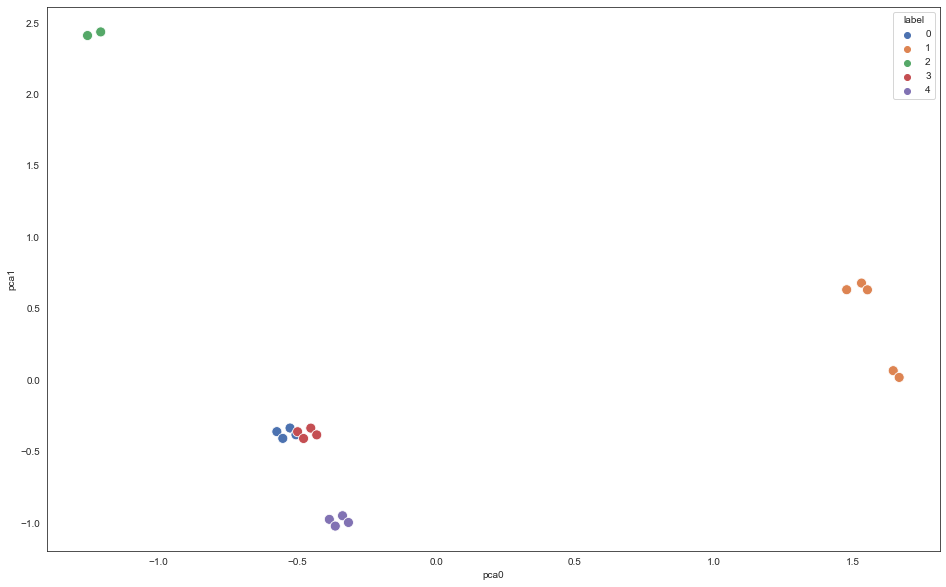

In [81]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style("white")
fig, ax = plt.subplots(figsize=(16, 10))
unique_df['label'] = clustering.labels_
sns.scatterplot(data=unique_df, x='pca0', y='pca1', hue='label', s=100,palette='deep', ax=ax)

In [82]:
unique_df

,path,str_paths,norm_tr_prob,norm_vi_prob,"(0, 0)","(0, 1)","(0, 2)","(0, 3)","(0, 4)","(0, 5)",...,"(4, 8)","(5, 0)","(5, 1)","(5, 2)","(5, 3)","(5, 4)","(5, 5)","(5, 6)","(5, 7)","(5, 8)"
3151,"[s004, s007, s006, s010, s013, s015, s016, s01...",['s004' 's007' 's006' 's010' 's013' 's015' 's0...,-0.785700,-3.835633,0.964315,1.049631,1.067875,1.244992,0.982752,0.941228,...,57.550575,209.235152,176.272964,161.116467,164.534953,154.130072,88.009597,176.515700,148.103850,152.052186
350,"[s004, s007, s006, s010, s013, s015, s017, s02...",['s004' 's007' 's006' 's010' 's013' 's015' 's0...,-0.638101,-1.894206,0.964315,1.049631,1.067875,1.244992,0.982752,0.941228,...,57.550575,209.235152,176.272964,161.116467,164.534953,154.130072,88.009597,157.476250,164.560775,152.052186
35,"[s004, s007, s006, s010, s013, s015, s017, s02...",['s004' 's007' 's006' 's010' 's013' 's015' 's0...,-0.631006,-1.406167,0.964315,1.049631,1.067875,1.244992,0.982752,0.941228,...,63.222983,209.235152,176.272964,161.116467,164.534953,154.130072,88.009597,157.476250,164.560775,148.834153
102,"[s004, s007, s006, s010, s013, s015, s017, s02...",['s004' 's007' 's006' 's010' 's013' 's015' 's0...,-0.632869,-1.212647,0.964315,1.049631,1.067875,1.244992,0.982752,0.941228,...,57.550575,209.235152,176.272964,161.116467,164.534953,154.130072,88.009597,157.476250,152.660547,152.052186
2,"[s004, s007, s006, s010, s013, s015, s017, s02...",['s004' 's007' 's006' 's010' 's013' 's015' 's0...,-0.639735,-1.087867,0.964315,1.049631,1.067875,1.244992,0.982752,0.941228,...,63.222983,209.235152,176.272964,161.116467,164.534953,154.130072,88.009597,157.476250,152.660547,148.834153
1059,"[s004, s007, s006, s010, s013, s015, s018, s02...",['s004' 's007' 's006' 's010' 's013' 's015' 's0...,-0.650559,-2.894965,0.964315,1.049631,1.067875,1.244992,0.982752,0.941228,...,57.550575,209.235152,176.272964,161.116467,164.534953,154.130072,88.009597,167.360563,164.560775,152.052186
173,"[s004, s007, s006, s010, s013, s015, s018, s02...",['s004' 's007' 's006' 's010' 's013' 's015' 's0...,-0.618616,-2.259703,0.964315,1.049631,1.067875,1.244992,0.982752,0.941228,...,63.222983,209.235152,176.272964,161.116467,164.534953,154.130072,88.009597,167.360563,164.560775,148.834153
3170,"[s004, s007, s006, s011, s013, s015, s016, s01...",['s004' 's007' 's006' 's011' 's013' 's015' 's0...,-0.836465,-3.626136,0.964315,1.049631,1.067875,1.238520,0.982752,0.941228,...,57.550575,209.235152,176.272964,161.116467,168.387037,154.130072,88.009597,176.515700,148.103850,152.052186
258,"[s004, s007, s006, s011, s013, s015, s017, s02...",['s004' 's007' 's006' 's011' 's013' 's015' 's0...,-0.636057,-1.760519,0.964315,1.049631,1.067875,1.238520,0.982752,0.941228,...,57.550575,209.235152,176.272964,161.116467,168.387037,154.130072,88.009597,157.476250,164.560775,152.052186
23,"[s004, s007, s006, s011, s013, s015, s017, s02...",['s004' 's007' 's006' 's011' 's013' 's015' 's0...,-0.633141,-1.224149,0.964315,1.049631,1.067875,1.238520,0.982752,0.941228,...,63.222983,209.235152,176.272964,161.116467,168.387037,154.130072,88.009597,157.476250,164.560775,148.834153


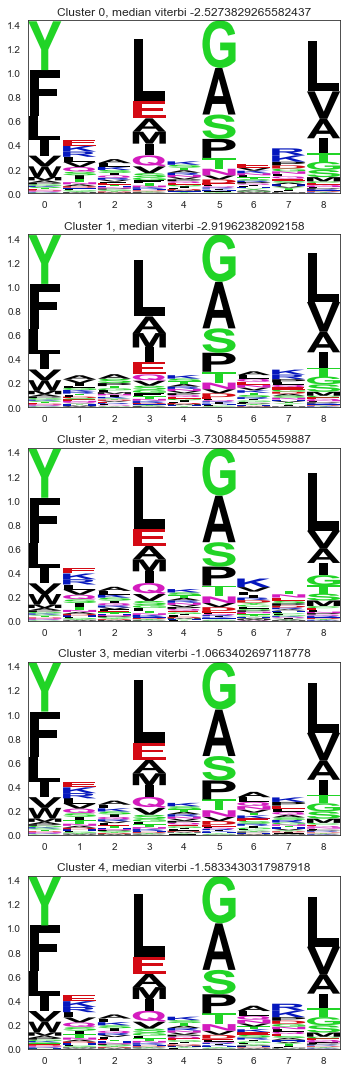

In [83]:
import logomaker
import matplotlib.pyplot as plt
unique_labels = np.unique(clustering.labels_)
fig, axes = plt.subplots(nrows=len(unique_labels), ncols=1, figsize=(5, 3*len(unique_labels)))
for label in unique_labels:
    filtered_for_label = unique_df[unique_df['label'] == label]
    matrix = np.zeros(shape=(9,20))
    for i in range(9):
        row_for_position = np.mean(np.stack(filtered_for_label['path'].map(lambda x :x[i]).apply(lambda state_name : np.array(list(state_name_to_distr[state_name].values())))), axis=0)

        matrix[i, :] = row_for_position
    matrix = pd.DataFrame(matrix, columns=state_name_to_distr['s000'].keys())

    info_matrix = logomaker.transform_matrix(matrix, from_type='probability', to_type='information')
    ww_logo = logomaker.Logo(info_matrix,
                             # font_name='Arial Rounded MT Bold',
                             ax=axes[label]
                             )
    mean_viterbi_prob = filtered_for_label['norm_vi_prob'].median()
    ww_logo.ax.set_title(f"Cluster {label}, median viterbi {mean_viterbi_prob}")
plt.tight_layout()



In [67]:
matrix = pd.DataFrame(matrix, columns=state_name_to_distr['s000'].keys())

In [71]:
unique_df = unique_df[unique_df['label'] == 2]

In [70]:
filtered_for_label


,path,str_paths,norm_tr_prob,norm_vi_prob,"(0, 0)","(0, 1)","(0, 2)","(0, 3)","(0, 4)","(0, 5)",...,"(4, 8)","(5, 0)","(5, 1)","(5, 2)","(5, 3)","(5, 4)","(5, 5)","(5, 6)","(5, 7)","(5, 8)"
3151,"[s004, s007, s006, s010, s013, s015, s016, s01...",['s004' 's007' 's006' 's010' 's013' 's015' 's0...,-0.785700,-3.835633,0.964315,1.049631,1.067875,1.244992,0.982752,0.941228,...,57.550575,209.235152,176.272964,161.116467,164.534953,154.130072,88.009597,176.515700,148.103850,152.052186
350,"[s004, s007, s006, s010, s013, s015, s017, s02...",['s004' 's007' 's006' 's010' 's013' 's015' 's0...,-0.638101,-1.894206,0.964315,1.049631,1.067875,1.244992,0.982752,0.941228,...,57.550575,209.235152,176.272964,161.116467,164.534953,154.130072,88.009597,157.476250,164.560775,152.052186
35,"[s004, s007, s006, s010, s013, s015, s017, s02...",['s004' 's007' 's006' 's010' 's013' 's015' 's0...,-0.631006,-1.406167,0.964315,1.049631,1.067875,1.244992,0.982752,0.941228,...,63.222983,209.235152,176.272964,161.116467,164.534953,154.130072,88.009597,157.476250,164.560775,148.834153
102,"[s004, s007, s006, s010, s013, s015, s017, s02...",['s004' 's007' 's006' 's010' 's013' 's015' 's0...,-0.632869,-1.212647,0.964315,1.049631,1.067875,1.244992,0.982752,0.941228,...,57.550575,209.235152,176.272964,161.116467,164.534953,154.130072,88.009597,157.476250,152.660547,152.052186
2,"[s004, s007, s006, s010, s013, s015, s017, s02...",['s004' 's007' 's006' 's010' 's013' 's015' 's0...,-0.639735,-1.087867,0.964315,1.049631,1.067875,1.244992,0.982752,0.941228,...,63.222983,209.235152,176.272964,161.116467,164.534953,154.130072,88.009597,157.476250,152.660547,148.834153
1059,"[s004, s007, s006, s010, s013, s015, s018, s02...",['s004' 's007' 's006' 's010' 's013' 's015' 's0...,-0.650559,-2.894965,0.964315,1.049631,1.067875,1.244992,0.982752,0.941228,...,57.550575,209.235152,176.272964,161.116467,164.534953,154.130072,88.009597,167.360563,164.560775,152.052186
173,"[s004, s007, s006, s010, s013, s015, s018, s02...",['s004' 's007' 's006' 's010' 's013' 's015' 's0...,-0.618616,-2.259703,0.964315,1.049631,1.067875,1.244992,0.982752,0.941228,...,63.222983,209.235152,176.272964,161.116467,164.534953,154.130072,88.009597,167.360563,164.560775,148.834153
3170,"[s004, s007, s006, s011, s013, s015, s016, s01...",['s004' 's007' 's006' 's011' 's013' 's015' 's0...,-0.836465,-3.626136,0.964315,1.049631,1.067875,1.238520,0.982752,0.941228,...,57.550575,209.235152,176.272964,161.116467,168.387037,154.130072,88.009597,176.515700,148.103850,152.052186
258,"[s004, s007, s006, s011, s013, s015, s017, s02...",['s004' 's007' 's006' 's011' 's013' 's015' 's0...,-0.636057,-1.760519,0.964315,1.049631,1.067875,1.238520,0.982752,0.941228,...,57.550575,209.235152,176.272964,161.116467,168.387037,154.130072,88.009597,157.476250,164.560775,152.052186
23,"[s004, s007, s006, s011, s013, s015, s017, s02...",['s004' 's007' 's006' 's011' 's013' 's015' 's0...,-0.633141,-1.224149,0.964315,1.049631,1.067875,1.238520,0.982752,0.941228,...,63.222983,209.235152,176.272964,161.116467,168.387037,154.130072,88.009597,157.476250,164.560775,148.834153


In [358]:
np.median(np.stack(filtered_for_label['path'].map(lambda x :x[0]).apply(lambda state_name : np.array(list(state_name_to_distr[state_name].values())))), axis=0)

array([0.01364989, 0.00324261, 0.00426017, 0.00455157, 0.26417121,
       0.00838314, 0.0025535 , 0.08992626, 0.00709201, 0.14305411,
       0.01946462, 0.00400951, 0.00904176, 0.00378286, 0.0033262 ,
       0.0066231 , 0.00546206, 0.06206799, 0.06198376, 0.28335366])

In [254]:
state_name_to_distr['s000'].items()

dict_items([('A', 0.061558684181611194), ('C', 0.0034154043367003047), ('D', 0.06582072220736726), ('E', 0.11433098137140396), ('F', 0.009948549788608547), ('G', 0.07893487314147149), ('H', 0.028638198565714715), ('I', 0.02673350729465692), ('K', 0.12694052422042057), ('L', 0.05047414429981772), ('M', 0.008463054128062688), ('N', 0.04843883693895788), ('P', 0.0494221963926069), ('Q', 0.05914391027977025), ('R', 0.07322784799075797), ('S', 0.11806425198177181), ('T', 0.03396758250514504), ('V', 0.024859760399039425), ('W', 0.004881919269480698), ('Y', 0.01273505070662236)])

In [255]:
aaindex[IMPORTANT_PROPERTIES_FROM_PAPER[0]]

{'description': 'Alpha-helix indices for beta-proteins (Geisow-Roberts, 1980)',
 'notes': '',
 'refs': "Geisow, M.J. and Roberts, R.D.B. 'Amino acid preferences for secondary structure vary with protein class' Int. J. Biol. Macromol. 2, 387-389 (1980); Kawashima, S. and Kanehisa, M.                     'AAindex: amino acid index database.'  Nucleic Acids Res. 28, 374 (2000).",
 'values': {'-': 0,
  'A': 1.55,
  'C': 1.44,
  'D': 1.55,
  'E': 1.67,
  'F': 0.4,
  'G': 0.59,
  'H': 1.21,
  'I': 1.27,
  'K': 1.2,
  'L': 1.25,
  'M': 1.37,
  'N': 1.2,
  'P': 0.21,
  'Q': 1.13,
  'R': 0.2,
  'S': 1.01,
  'T': 0.55,
  'V': 0.64,
  'W': 1.86,
  'Y': 1.08}}

In [242]:
state_name_to_distr

{'s000': {'A': 0.061558684181611194,
  'C': 0.0034154043367003047,
  'D': 0.06582072220736726,
  'E': 0.11433098137140396,
  'F': 0.009948549788608547,
  'G': 0.07893487314147149,
  'H': 0.028638198565714715,
  'I': 0.02673350729465692,
  'K': 0.12694052422042057,
  'L': 0.05047414429981772,
  'M': 0.008463054128062688,
  'N': 0.04843883693895788,
  'P': 0.0494221963926069,
  'Q': 0.05914391027977025,
  'R': 0.07322784799075797,
  'S': 0.11806425198177181,
  'T': 0.03396758250514504,
  'V': 0.024859760399039425,
  'W': 0.004881919269480698,
  'Y': 0.01273505070662236},
 's001': {'A': 0.058733630183567836,
  'C': 0.003714320000532187,
  'D': 0.0867890120400746,
  'E': 0.020038443242182406,
  'F': 0.005066909405959764,
  'G': 0.22115660608792992,
  'H': 0.02637607001739253,
  'I': 0.014179646590920764,
  'K': 0.04723919537084697,
  'L': 0.0428879209077893,
  'M': 0.017864645289127144,
  'N': 0.10652791038018258,
  'P': 0.11532248031290852,
  'Q': 0.04530374702178226,
  'R': 0.02877275615